# H6 · Un modelo más fuerte en Stage 1 lee mejor la pizarra

**Hipótesis.** Si el límite del sistema estuviera en leer el dibujo, Gemini Pro o Claude Opus en Stage 1
deberían coincidir más que Flash con la transcripción que hizo una persona, y acercarse más al ground truth.

**Veredicto: rechazada.** Ninguno de los tres modelos lee la pizarra mejor que otro, ni con el
transcript ni con solo la imagen.

- **Con solo la pizarra** (la condición de la persona): conexiones F1 contra la persona 66,75 en
  Flash, 69,87 en Pro y 68,47 en Claude. Pro − Flash: +3,12 (IC 95 % [−2,36, +9,09]);
  Claude − Flash: +1,72 (IC [−5,15, +8,65]).
- **Con pizarra y transcript** (el Stage 1 de producción): 63,07 en Flash, 61,64 en Pro y 66,99 en Claude.
- **Contra el ground truth nadie se mueve:** las seis lecturas automáticas quedan entre 50,59 y
  53,34, frente a 57,60 de la persona.

**Lo que sí cambia.** Quitar el transcript acerca a los modelos de Gemini a la lectura humana
(+8,22 en Pro, IC [+0,36, +16,98]; +3,67 en Flash, IC [−4,86, +12,38]); a Claude casi no lo mueve
(+1,48, IC [−4,10, +7,25]). En ningún caso los acerca al ground truth.

## Archivos usados, cómo se generaron y dónde quedaron

| World Model | qué recibe Stage 1 | cómo se generó | dónde quedó |
|---|---|---|---|
| Persona | solo la pizarra | transcripción manual | `lab_workspace/<vid>/world_model_vision.json` (original en `data/manual_world_models/`) |
| Flash | pizarra + transcript | `.venv/Scripts/python scripts/ablation/stage1_panel.py run --model gemini-3.6-flash --name s1-flash` | `lab_workspace/<vid>/world_model_s1-flash.json` |
| Pro | pizarra + transcript | `.venv/Scripts/python scripts/ablation/stage1_panel.py run --model gemini-3.1-pro-preview --name s1-pro` | `lab_workspace/<vid>/world_model_s1-pro.json` |
| Flash | solo la pizarra | `.venv/Scripts/python scripts/ablation/stage1_panel.py run --model gemini-3.6-flash --name s1-flash-img --no-transcript` | `lab_workspace/<vid>/world_model_s1-flash-img.json` |
| Pro | solo la pizarra | `.venv/Scripts/python scripts/ablation/stage1_panel.py run --model gemini-3.1-pro-preview --name s1-pro-img --no-transcript` | `lab_workspace/<vid>/world_model_s1-pro-img.json` |

| Claude | pizarra + transcript | `.venv/Scripts/python scripts/ablation/stage1_panel.py run --model claude-opus-5-5 --name s1-claude` (vía `claude -p`) | `lab_workspace/<vid>/world_model_s1-claude.json` |
| Claude | solo la pizarra | `.venv/Scripts/python scripts/ablation/stage1_panel.py run --model claude-opus-5-5 --name s1-claude-img --no-transcript` | `lab_workspace/<vid>/world_model_s1-claude-img.json` |

`lab_workspace` es `whiteboard_selection_lab/lab_workspace/` y está fuera de git; los hashes de
cada World Model generado, el modelo y el prompt quedan en `reports/stage1_vs_manual/<nombre>/run.json`,
y los logs en `reports/stage1_vs_manual/<nombre>.log`.

La comparación sale de `.venv/Scripts/python scripts/ablation/stage1_panel.py compare --names s1-flash s1-pro s1-claude s1-flash-img s1-pro-img s1-claude-img` y queda en
`reports/stage1_vs_manual/comparacion.md`, `comparacion.json` y `results.csv`.

Prompt de Stage 1: `src/configs/prompts/stage1_v0_baseline.txt` (sha `497d30164f48`, el de producción),
con el bloque de símbolos del detector, igual que el pipeline. Pizarras: `data/good_whiteboard/<vid>.jpg`,
la misma imagen que transcribió la persona. Temperatura 0, una corrida por condición.
Figuras de este notebook: `hipotesis/figuras/H6_*.png`.

**Cómo se mide.** Cada World Model se reduce a su conjunto de servicios y al multiconjunto de pares
(servicio origen, servicio destino) de sus conexiones, igual que el evaluador. "Contra la persona" dice
cuánto coincide con la lectura humana; "contra el ground truth" es el techo que tendría Stage 2 si
copiara ese World Model sin tocarlo.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import comun as c

c.estilo()
from collections import Counter

MODELOS = ["s1-flash", "s1-pro", "s1-claude", "s1-flash-img", "s1-pro-img", "s1-claude-img"]
TODOS = ["vision"] + MODELOS
videos = list(c.s1_filas("vision"))
print(f"Control: la lectura de la persona contra el ground truth da "
      f"{c.s1_media('vision', 'svc_f1_vs_gt'):.2f} en servicios y {c.s1_media('vision', 'con_f1_vs_gt'):.2f} en conexiones "
      f"(Tabla VI del paper: 87,36 y 57,60).")
c.Tabla(["Stage 1", "entrada", "entidades", "conexiones", "servicios F1 vs persona", "conexiones F1 vs persona",
         "servicios F1 vs GT", "conexiones F1 vs GT"],
        [[c.S1[n][0], c.S1[n][2], f"{c.s1_media(n, 'entidades'):.2f}", f"{c.s1_media(n, 'conexiones'):.2f}",
          f"{c.s1_media(n, 'svc_f1_vs_manual'):.2f}", f"{c.s1_media(n, 'con_f1_vs_manual'):.2f}",
          f"{c.s1_media(n, 'svc_f1_vs_gt'):.2f}", f"{c.s1_media(n, 'con_f1_vs_gt'):.2f}"] for n in TODOS])

Control: la lectura de la persona contra el ground truth da 87.36 en servicios y 57.60 en conexiones (Tabla VI del paper: 87,36 y 57,60).


Stage 1,entrada,entidades,conexiones,servicios F1 vs persona,conexiones F1 vs persona,servicios F1 vs GT,conexiones F1 vs GT
Persona,solo la pizarra,9.00,8.63,100.00,100.00,87.36,57.60
Flash,pizarra + transcript,9.03,8.27,86.93,63.07,84.52,52.40
Pro,pizarra + transcript,9.67,8.90,86.39,61.64,83.18,50.59
Claude,pizarra + transcript,9.40,8.73,84.36,66.99,81.02,52.81
Flash,solo la pizarra,8.83,8.17,89.49,66.75,85.74,53.34
Pro,solo la pizarra,9.40,8.37,91.79,69.87,83.24,52.72
Claude,solo la pizarra,9.33,8.57,86.24,68.47,82.73,52.31


## 1 · Cuánto coincide cada modelo con lo que leyó la persona

Color pleno: Stage 1 recibe la pizarra y el transcript. Color claro: solo la pizarra, que es la
condición en la que trabajó la persona.

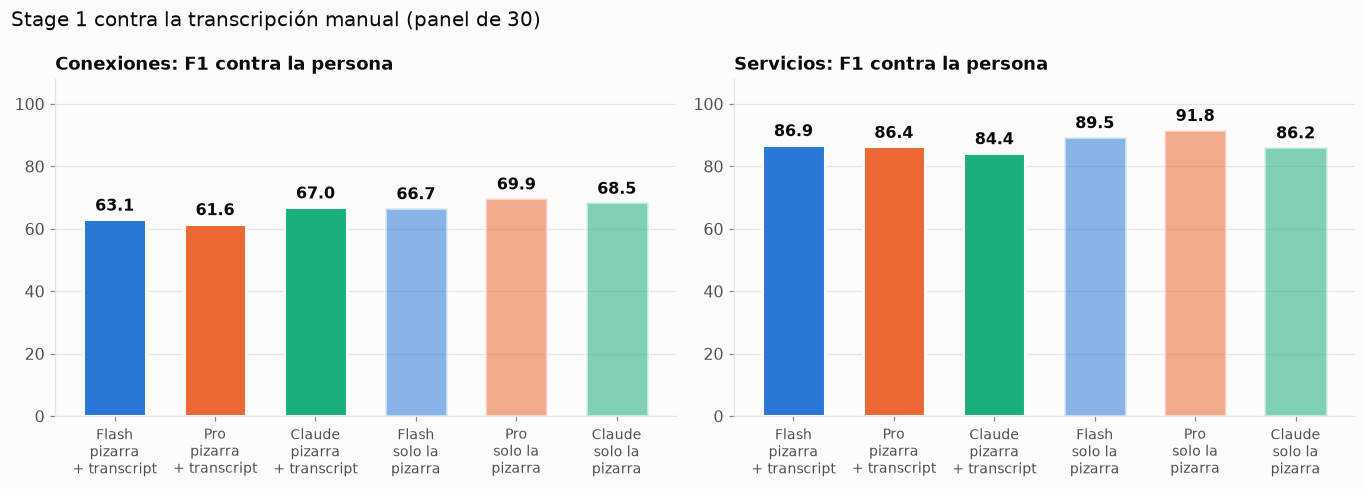

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.5))
c.s1_barras(ax[0], MODELOS, "con_f1_vs_manual", "Conexiones: F1 contra la persona")
c.s1_barras(ax[1], MODELOS, "svc_f1_vs_manual", "Servicios: F1 contra la persona")
fig.suptitle("Stage 1 contra la transcripción manual (panel de 30)", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
c.guardar(fig, "H6_contra_la_persona")

## 2 · Cuánto se acerca cada lectura al ground truth

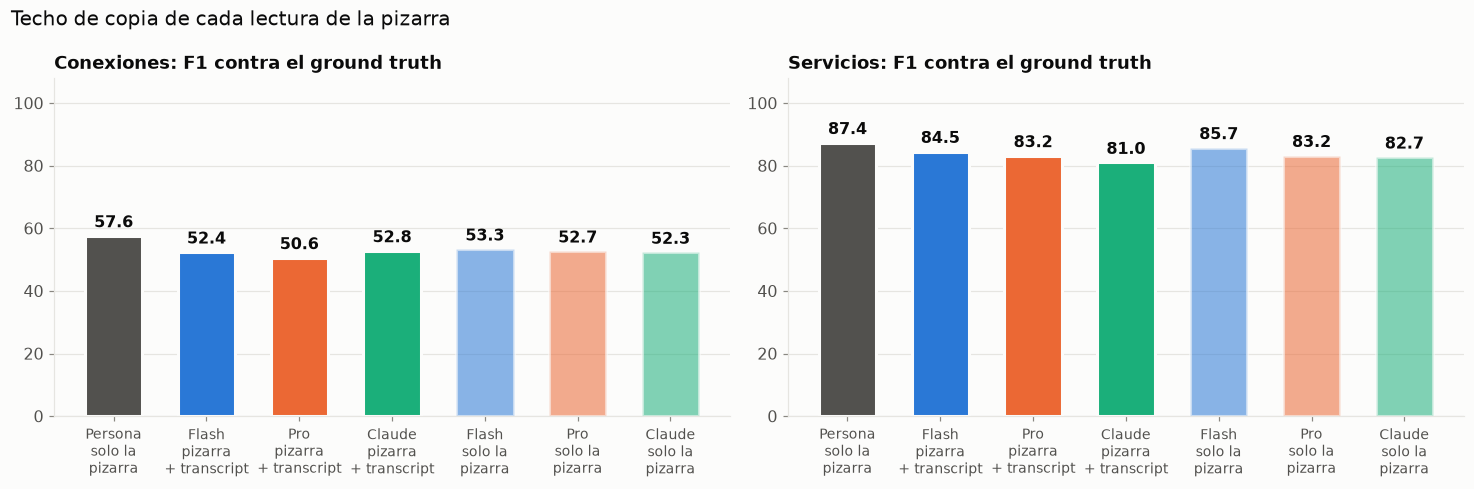

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.5))
c.s1_barras(ax[0], TODOS, "con_f1_vs_gt", "Conexiones: F1 contra el ground truth")
c.s1_barras(ax[1], TODOS, "svc_f1_vs_gt", "Servicios: F1 contra el ground truth")
fig.suptitle("Techo de copia de cada lectura de la pizarra", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
c.guardar(fig, "H6_contra_el_ground_truth")

## 3 · Las diferencias, video por video

Cada fila es una diferencia pareada sobre los 30 videos con su intervalo del 95 %.

comparación (B − A),Δ,IC 95 %,gana / pierde / empata,p (signos)
Pro − Flash con transcript · vs persona,-1.43,"[-11.45, +7.95]",11 / 13 / 6,0.839
Pro − Flash solo pizarra · vs persona,+3.12,"[-2.36, +9.09]",11 / 11 / 8,1.000
Claude − Flash solo pizarra · vs persona,+1.72,"[-5.15, +8.65]",14 / 12 / 4,0.845
Flash: solo pizarra − con transcript vs persona,+3.67,"[-4.86, +12.38]",14 / 11 / 5,0.690
Pro: solo pizarra − con transcript vs persona,+8.22,"[+0.36, +16.98]",15 / 7 / 8,0.134
Claude: solo pizarra − con transcript vs persona,+1.48,"[-4.10, +7.25]",8 / 5 / 17,0.581
Persona − Flash solo pizarra vs ground truth,+4.26,"[-1.65, +10.29]",15 / 11 / 4,0.557
Persona − Pro solo pizarra vs ground truth,+4.88,"[+0.78, +9.23]",15 / 9 / 6,0.307
Persona − Claude solo pizarra vs ground truth,+5.29,"[+0.74, +9.83]",18 / 6 / 6,0.023
Claude: solo pizarra − con transcript vs ground truth,-0.51,"[-4.61, +3.49]",7 / 6 / 17,1.000


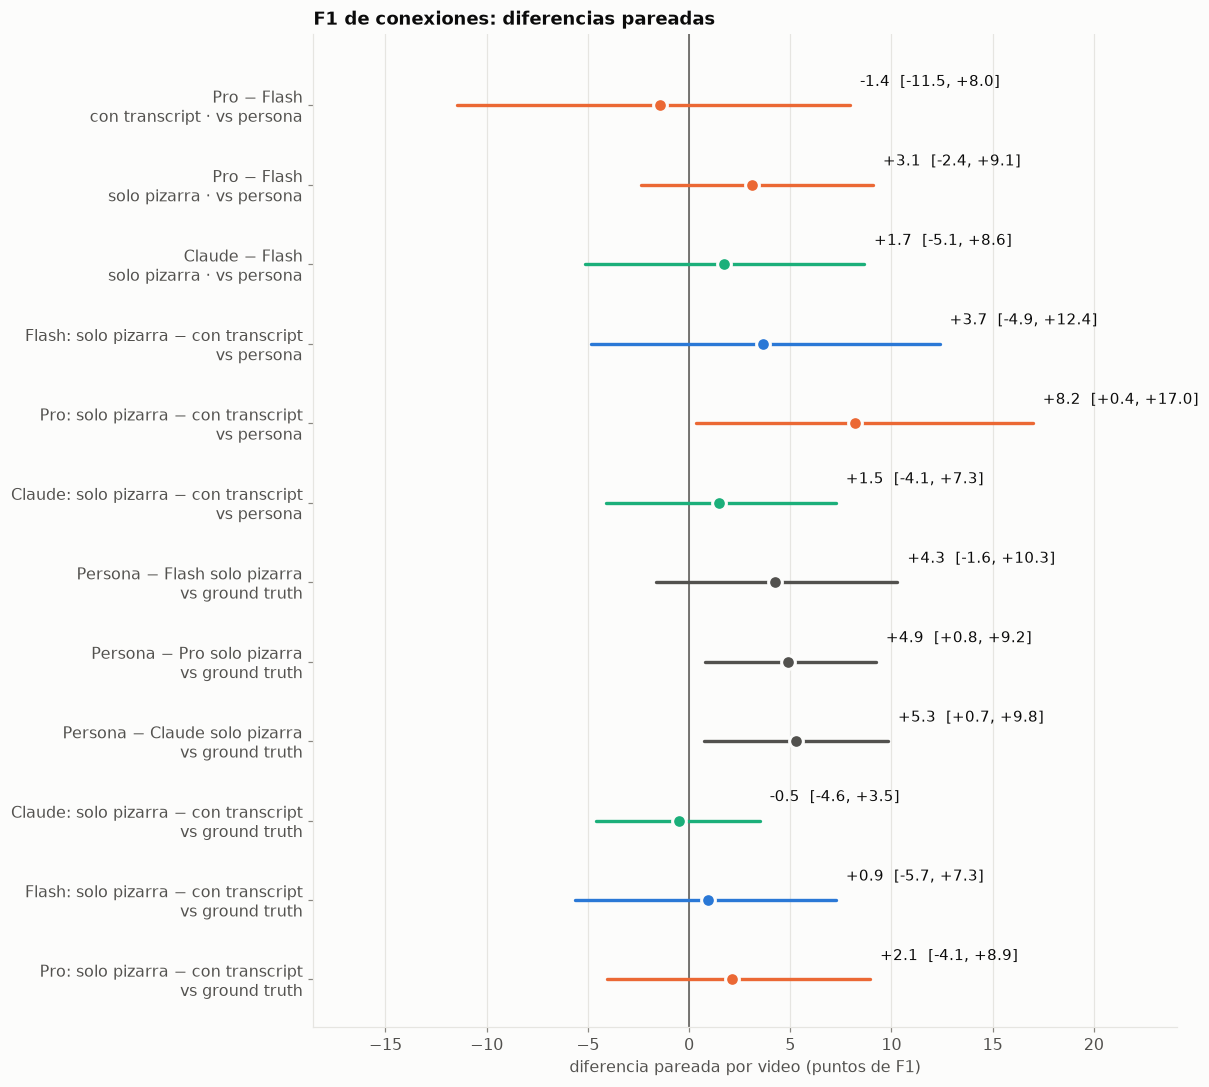

In [4]:
comp = [
    ("s1-flash", "s1-pro", "con_f1_vs_manual", "Pro − Flash\ncon transcript · vs persona"),
    ("s1-flash-img", "s1-pro-img", "con_f1_vs_manual", "Pro − Flash\nsolo pizarra · vs persona"),
    ("s1-flash-img", "s1-claude-img", "con_f1_vs_manual", "Claude − Flash\nsolo pizarra · vs persona"),
    ("s1-flash", "s1-flash-img", "con_f1_vs_manual", "Flash: solo pizarra − con transcript\nvs persona"),
    ("s1-pro", "s1-pro-img", "con_f1_vs_manual", "Pro: solo pizarra − con transcript\nvs persona"),
    ("s1-claude", "s1-claude-img", "con_f1_vs_manual", "Claude: solo pizarra − con transcript\nvs persona"),
    ("s1-flash-img", "vision", "con_f1_vs_gt", "Persona − Flash solo pizarra\nvs ground truth"),
    ("s1-pro-img", "vision", "con_f1_vs_gt", "Persona − Pro solo pizarra\nvs ground truth"),
    ("s1-claude-img", "vision", "con_f1_vs_gt", "Persona − Claude solo pizarra\nvs ground truth"),
    ("s1-claude", "s1-claude-img", "con_f1_vs_gt", "Claude: solo pizarra − con transcript\nvs ground truth"),
    ("s1-flash", "s1-flash-img", "con_f1_vs_gt", "Flash: solo pizarra − con transcript\nvs ground truth"),
    ("s1-pro", "s1-pro-img", "con_f1_vs_gt", "Pro: solo pizarra − con transcript\nvs ground truth"),
]
fig, ax = plt.subplots(figsize=(11, 10))
c.s1_bosque(ax, comp, titulo="F1 de conexiones: diferencias pareadas")
fig.tight_layout()
c.guardar(fig, "H6_diferencias")
c.s1_tabla_pareada(comp)

## 4 · Qué conexiones ve cada uno

Para cada modelo, las conexiones se reparten en tres grupos: las que dibujan el modelo y la persona,
las que solo dibuja el modelo y las que solo dibuja la persona. La parte en color pleno es la que
además está en el ground truth.

Stage 1,grupo,conexiones,en el ground truth,%
Flash · pizarra + transcript,solo la persona,98,42,43 %
Flash · pizarra + transcript,solo el modelo,87,25,29 %
Flash · pizarra + transcript,las ven los dos,161,135,84 %
Pro · pizarra + transcript,solo la persona,103,49,48 %
Pro · pizarra + transcript,solo el modelo,111,25,23 %
Pro · pizarra + transcript,las ven los dos,156,128,82 %
Claude · pizarra + transcript,solo la persona,89,36,40 %
Claude · pizarra + transcript,solo el modelo,88,20,23 %
Claude · pizarra + transcript,las ven los dos,170,141,83 %
Flash · solo la pizarra,solo la persona,98,44,45 %


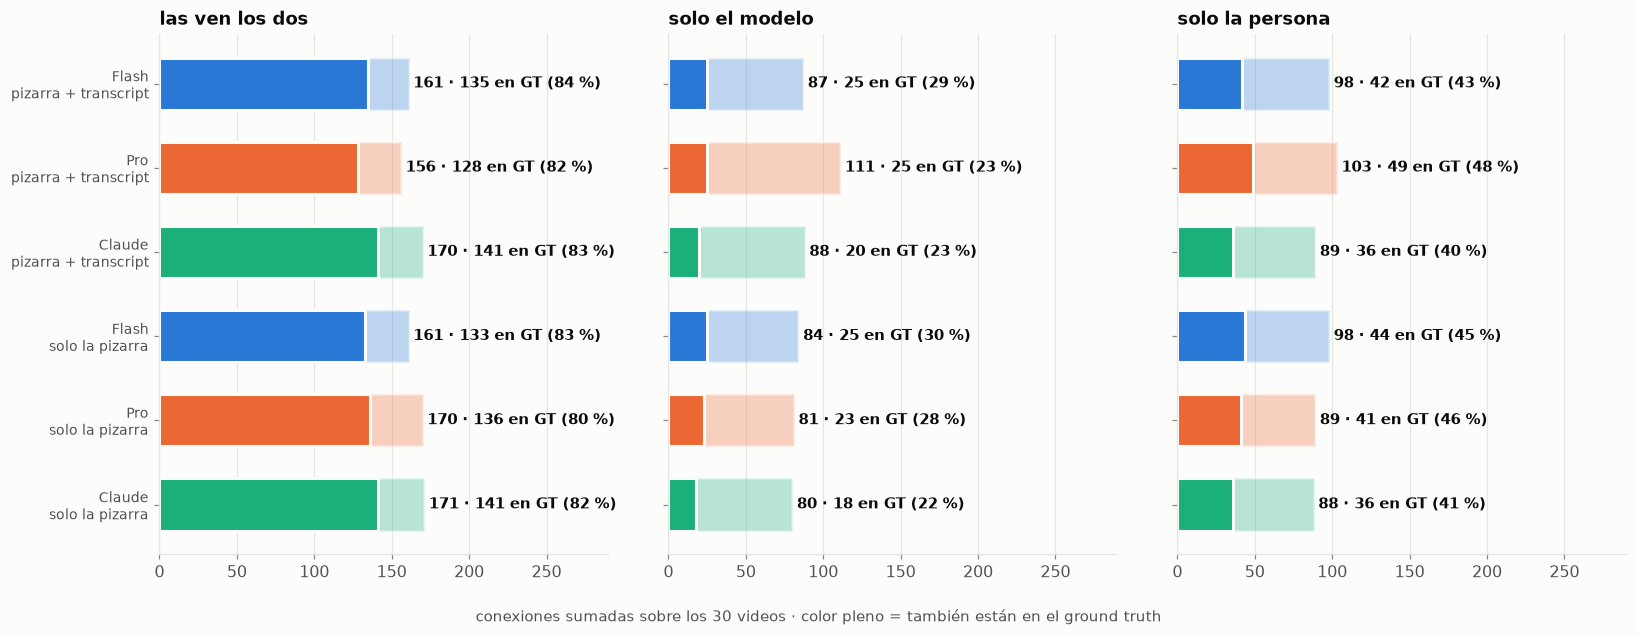

In [5]:
def reparto(nombre):
    grupos = {"las ven los dos": [0, 0], "solo el modelo": [0, 0], "solo la persona": [0, 0]}
    for v in videos:
        m, p, g = c.wm_reducido(v, nombre)[1], c.wm_reducido(v, "vision")[1], c.gt(v)[1]
        ambos = m & p
        for clave, conj, resto in (("las ven los dos", ambos, g), ("solo el modelo", m - p, g - ambos),
                                   ("solo la persona", p - m, g - ambos)):
            grupos[clave][0] += sum(conj.values())
            grupos[clave][1] += sum((conj & resto).values())
    return grupos

fig, ax = plt.subplots(1, 3, figsize=(15, 5.8), sharey=True)
tabla = []
for y, n in enumerate(reversed(MODELOS)):
    for a, (clave, (total, en_gt)) in zip(ax, reparto(n).items()):
        a.barh(y, total, height=0.62, color=c.S1[n][1], alpha=0.3, edgecolor=c.FONDO, linewidth=2)
        a.barh(y, en_gt, height=0.62, color=c.S1[n][1], edgecolor=c.FONDO, linewidth=2)
        a.text(total + 3, y, f"{total} · {en_gt} en GT ({100 * en_gt / total:.0f} %)", va="center", fontweight="bold", fontsize=9.5)
        a.set_title(clave)
        a.set_xlim(0, 290)
        a.grid(axis="y", visible=False)
        tabla.append([c.s1_etiqueta(n, " · "), clave, total, en_gt, f"{100 * en_gt / total:.0f} %"])
ax[0].set_yticks(range(len(MODELOS)), [c.s1_etiqueta(n) for n in reversed(MODELOS)], fontsize=9)
fig.supxlabel("conexiones sumadas sobre los 30 videos · color pleno = también están en el ground truth", fontsize=10, color=c.TINTA2)
fig.tight_layout()
c.guardar(fig, "H6_reparto_de_conexiones")
c.Tabla(["Stage 1", "grupo", "conexiones", "en el ground truth", "%"], tabla[::-1])

## 5 · Por video: la persona contra cada modelo, frente al ground truth

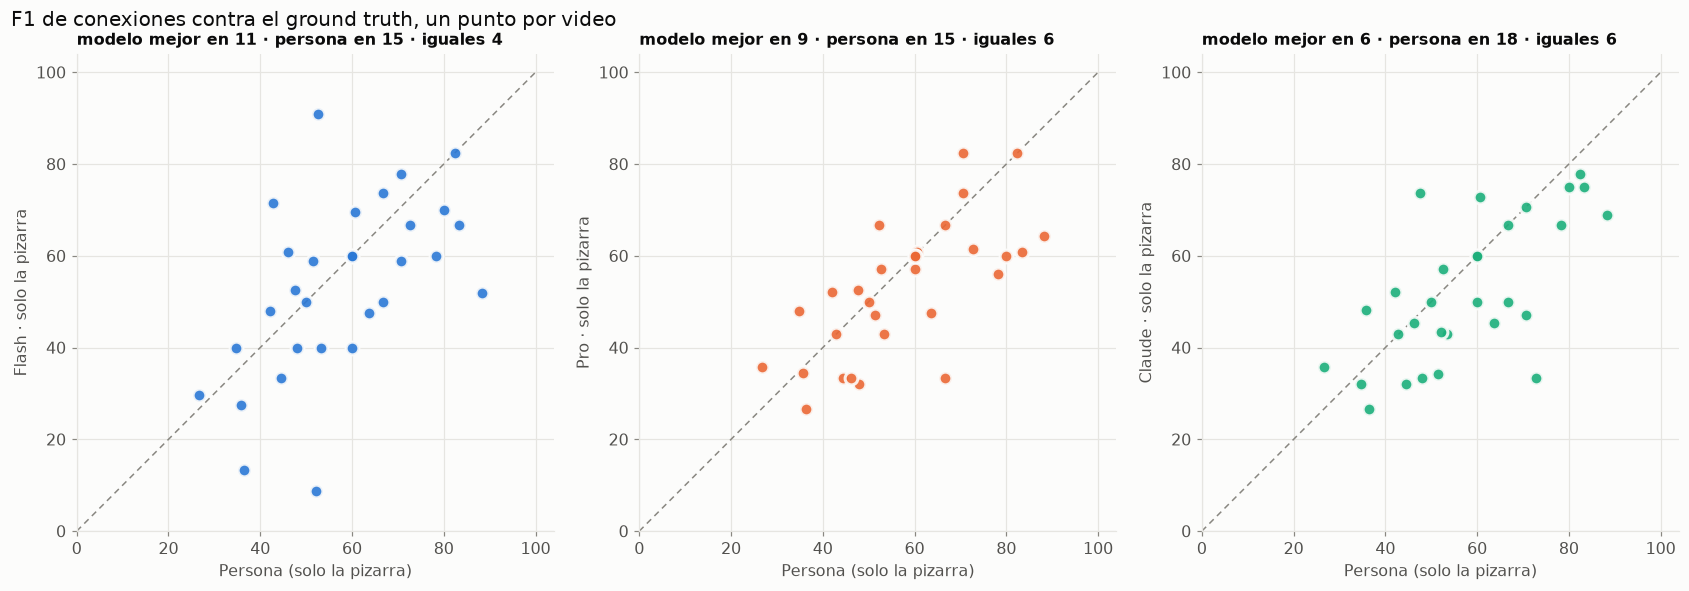

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15.5, 5.2))
for a, n in zip(ax, ["s1-flash-img", "s1-pro-img", "s1-claude-img"]):
    x = [100 * c.s1_filas("vision")[v]["con_f1_vs_gt"] for v in videos]
    y = [100 * c.s1_filas(n)[v]["con_f1_vs_gt"] for v in videos]
    a.plot([0, 100], [0, 100], color=c.TENUE, linewidth=1, linestyle=(0, (4, 3)))
    a.scatter(x, y, s=70, color=c.S1[n][1], edgecolor=c.FONDO, linewidth=2, alpha=0.9, zorder=3)
    a.set_xlim(0, 104); a.set_ylim(0, 104); a.set_aspect("equal")
    a.set_xlabel("Persona (solo la pizarra)")
    a.set_ylabel(c.s1_etiqueta(n, " · "))
    arriba = sum(yy > xx + 1e-9 for xx, yy in zip(x, y)); abajo = sum(yy < xx - 1e-9 for xx, yy in zip(x, y))
    a.set_title(f"modelo mejor en {arriba} · persona en {abajo} · iguales {len(x) - arriba - abajo}", fontsize=10.5)
fig.suptitle("F1 de conexiones contra el ground truth, un punto por video", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
c.guardar(fig, "H6_por_video")

## 6 · Dos pizarras de ejemplo

La referencia de estos grafos es la lectura de la persona: rojo punteado es una conexión que la
persona dibujó y el modelo no; violeta, una que el modelo añadió.

Donde Pro (solo pizarra) menos coincide con la persona: hMK2NJ-q9nc


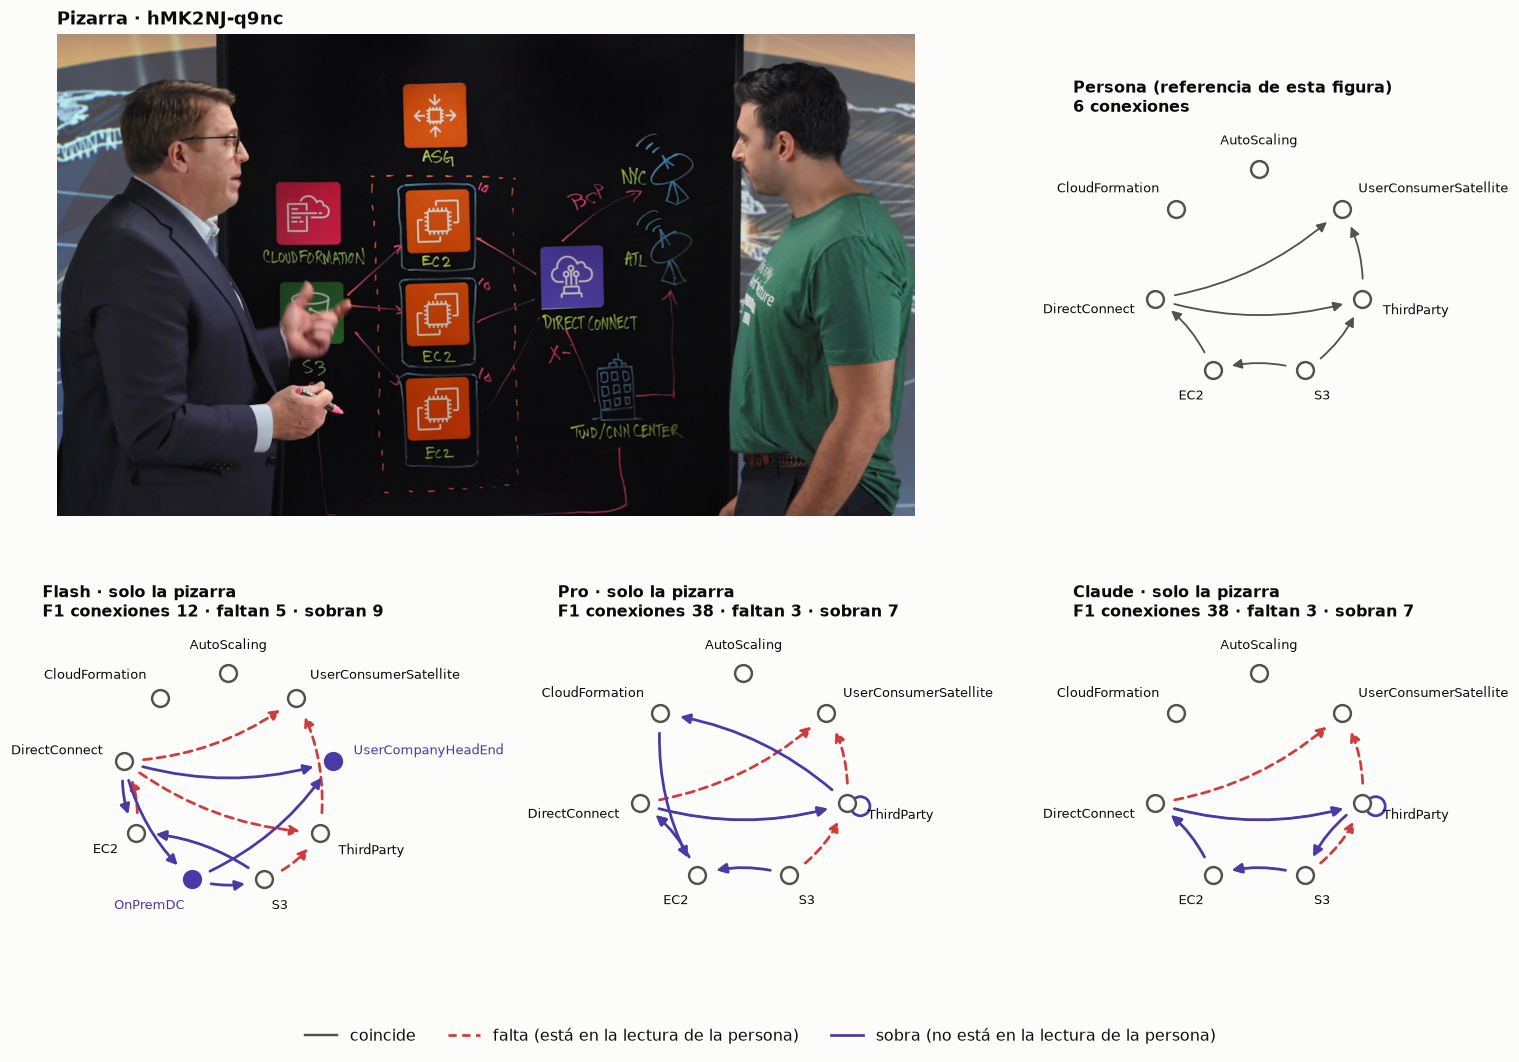

In [7]:
orden = sorted(videos, key=lambda v: c.s1_filas("s1-pro-img")[v]["con_f1_vs_manual"])
def ejemplo(vid, nombre_fig):
    fig = plt.figure(figsize=(14, 9.5))
    gs = fig.add_gridspec(2, 3)
    c.pizarra(fig.add_subplot(gs[0, :2]), vid)
    c.grafo_wm(fig.add_subplot(gs[0, 2]), vid, "vision", titulo="Persona (referencia de esta figura)")
    for i, n in enumerate(["s1-flash-img", "s1-pro-img", "s1-claude-img"]):
        c.grafo_wm(fig.add_subplot(gs[1, i]), vid, n)
    c.leyenda_grafo(fig, ref="la lectura de la persona")
    fig.tight_layout()
    c.guardar(fig, nombre_fig)

print("Donde Pro (solo pizarra) menos coincide con la persona:", orden[1])
ejemplo(orden[1], "H6_ejemplo_menor_coincidencia")

Donde Pro (solo pizarra) más coincide con la persona: f5EJBUfGZtw


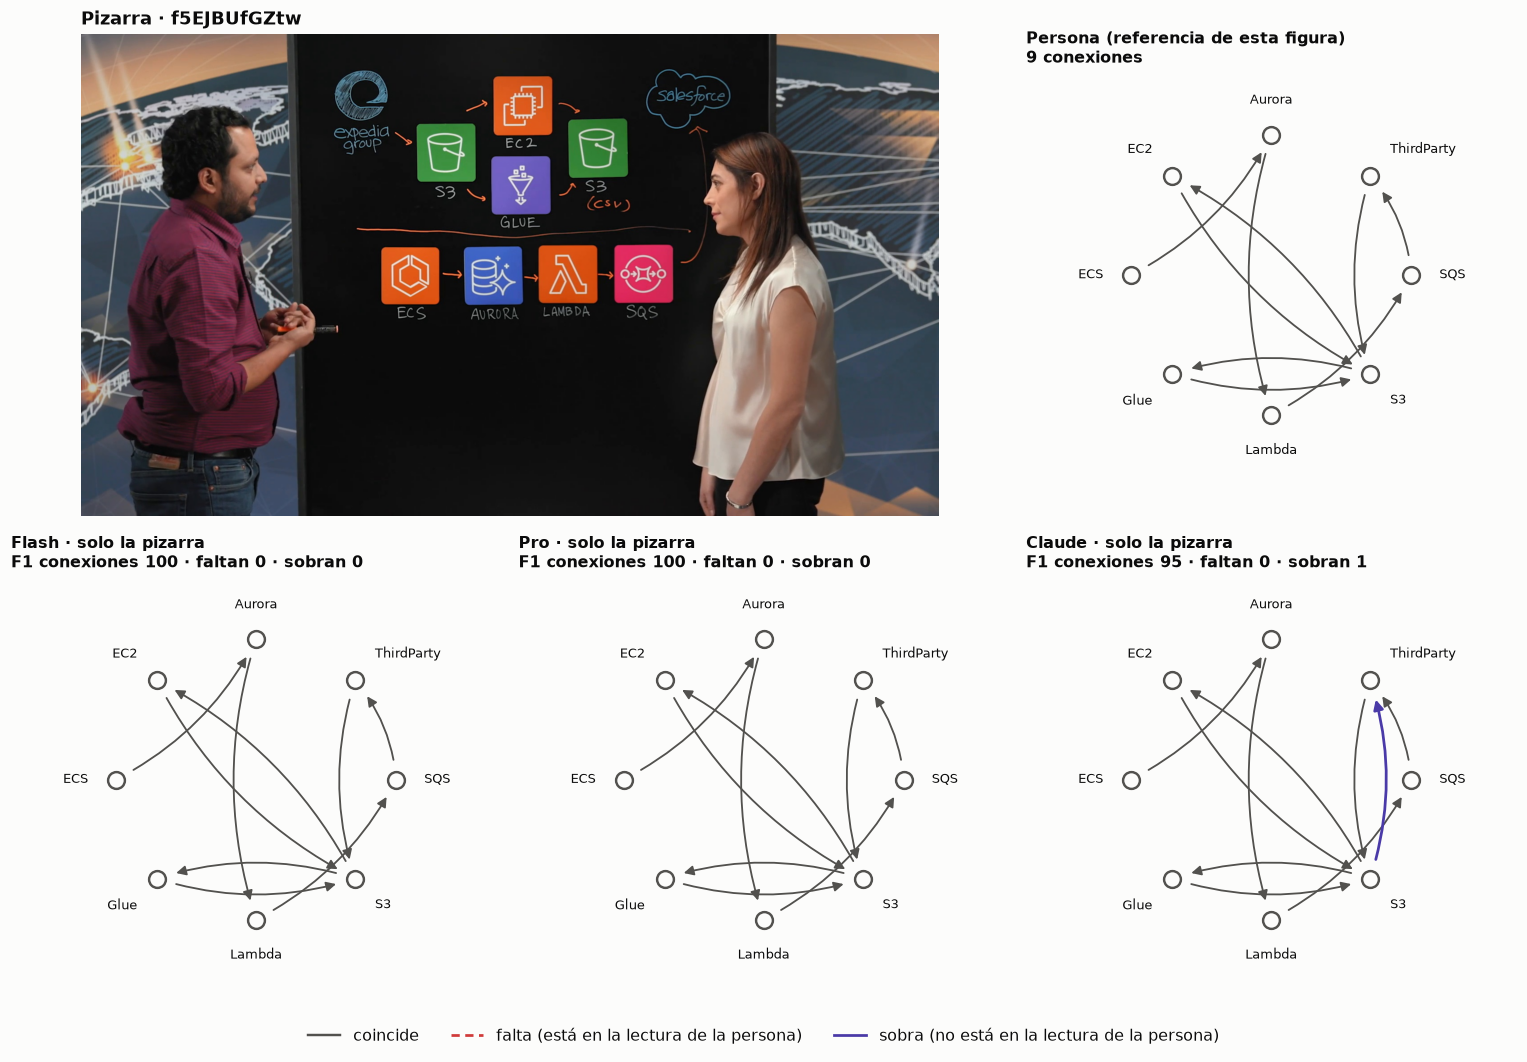

In [8]:
print("Donde Pro (solo pizarra) más coincide con la persona:", orden[-1])
ejemplo(orden[-1], "H6_ejemplo_mayor_coincidencia")

## Qué aporta al paper

- **El límite no es la capacidad de lectura.** Tres modelos de dos proveedores, con y sin audio,
  quedan todos entre 50,6 y 53,3 de F1 de conexiones contra el ground truth. La persona queda en 57,60.
- **La ventaja de la persona es pequeña:** con solo la pizarra, +5,29 sobre Claude (IC [+0,74, +9,83]),
  +4,88 sobre Pro (IC [+0,78, +9,23]) y +4,26 sobre Flash (IC [−1,65, +10,29]). Es coherente con la
  Tabla VI: no queda margen perceptual. Con el protocolo permisivo esa ventaja se reduce todavía más.
- **Las conexiones en las que modelo y persona coinciden son las fiables**; las que dibuja solo uno
  de los dos están en el ground truth con mucha menos frecuencia (figura de la sección 4).

**Salvedades.** Una corrida por condición. Flash y Pro corrieron a temperatura 0; a Claude no se le
puede fijar. En las lecturas de Claude, 4 y 6 conexiones (de unas 260) usan una etiqueta que no
corresponde a ninguna entidad y no se cuentan. El prompt de Stage 1 sigue mencionando el transcript en
las corridas que no lo reciben. Una sola persona hizo la transcripción manual, así que "coincidir con
la persona" mide acuerdo con un anotador, no con un consenso.